# Nexus NLP Studio: Opini Publik Aksi 28 Oktober
### End-to-End Competitive NLP Pipeline (EDA, Auto-Tune Ablation, CV & Interpretability)

**Pipeline Architecture**:
1. **Corpus & Target EDA**: Imbalance ratio analysis, word/character distributions, and vocabulary richness.
2. **Automated Hyperparameter Ablation**: Stratified ablation across N-Gram combinations (1-1 vs 1-2) and L2 penalty ($C \in [0.5, 1.0, 1.5, 2.5, 5.0]$).
3. **Stratified 5-Fold Cross-Validation**: Out-of-fold validation evaluating **Macro-F1** and **Accuracy** without data leakage.
4. **Diagnostic Confusion Matrix**: Error pattern heatmaps across sentiment classes.
5. **Model Interpretability**: Feature importance coefficients per class showing top informative keywords.

#### Mathematical Foundations
- **Balanced Class Weighting** (protecting minority classes against severe imbalance):
  $$w_c = \frac{N}{K \cdot N_c}$$
- **L2-Regularized Cross-Entropy Loss**:
  $$\min_{W, b} \frac{1}{2} \|W\|_F^2 + C \sum_{i=1}^N w_{y_i} \mathcal{L}_{CE}(f(x_i), y_i)$$


In [2]:
# 1. Environment Setup & Core Dependencies
import os
import sys
import time
import json
import warnings
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 110
print('Environment initialized successfully.')


Environment initialized successfully.


In [3]:
# 2. Dataset Ingestion & Configuration
TRAIN_PATH = 'cases/aksi_28_okt/train.csv'
TEST_PATH = ''
TEXT_COL = 'clean_text'
TARGET_COL = 'sentiment'
SEED = 2026

def resolve_path(p):
    if not p:
        return ''
    if os.path.exists(p):
        return p
    base = os.path.basename(p)
    for cand in [f'./{base}', f'../{base}', f'cases/{base}', f'/kaggle/input/**/{base}']:
        import glob
        m = glob.glob(cand, recursive=True)
        if m:
            return m[0]
    return p

train_df = pd.read_csv(resolve_path(TRAIN_PATH))
print(f'Training Corpus: {train_df.shape[0]:,} rows x {train_df.shape[1]} columns')
print(f'Text Column:   {TEXT_COL}')
print(f'Target Column: {TARGET_COL}')
display(train_df[[TEXT_COL, TARGET_COL]].head(5))


Training Corpus: 3,745 rows x 11 columns
Text Column:   clean_text
Target Column: sentiment


,clean_text,sentiment
0,"sebagai pemuda, saya malu belum bisa ikut turu...",Positif
1,"kalau tni dan polri ada yang baca ini,.. saya ...",Negatif
2,"begini lho mahasiswa klo ditanya2, jawaban jel...",Negatif
3,keren banget sih melihat anak muda dan berbaga...,Positif
4,b prabowo u anggota dpr n dan setiap keluargan...,Negatif


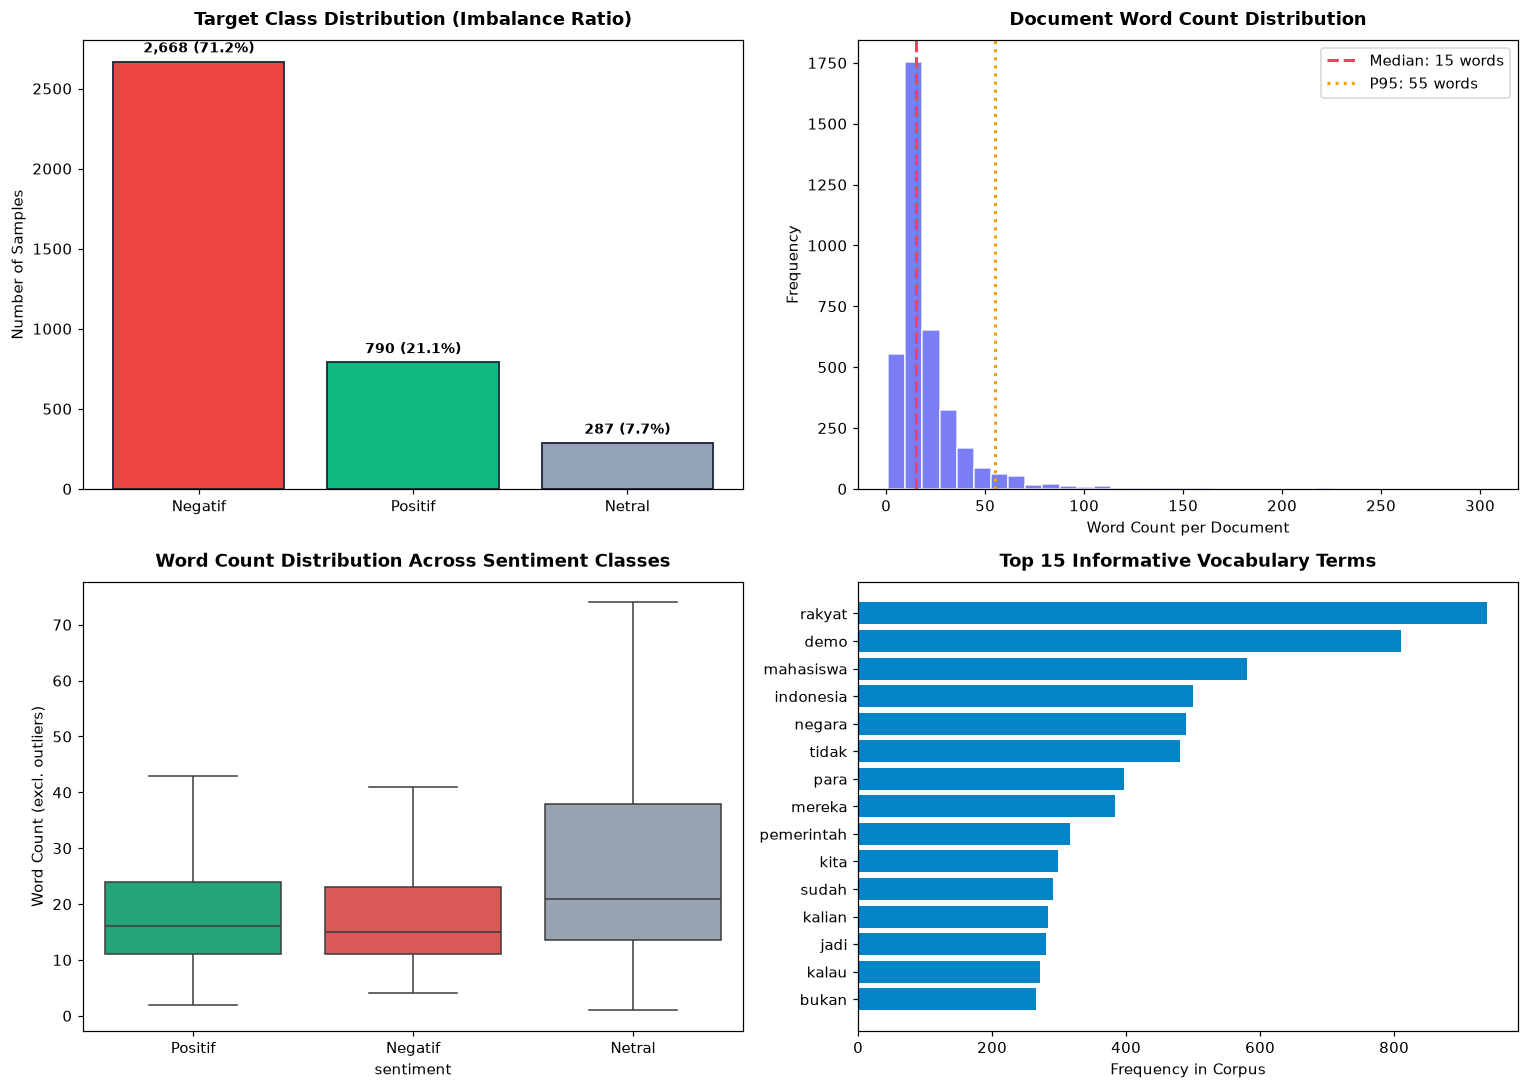

In [4]:
# 3. Corpus & Target EDA Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Target Class Distribution & Imbalance Ratio
class_counts = train_df[TARGET_COL].value_counts()
palette = {'Negatif': '#ef4444', 'Netral': '#94a3b8', 'Positif': '#10b981', 'negative': '#ef4444', 'neutral': '#94a3b8', 'positive': '#10b981'}
colors = [palette.get(c, '#3b82f6') for c in class_counts.index]
bars = axes[0, 0].bar(class_counts.index, class_counts.values, color=colors, edgecolor='#1e293b', linewidth=1.2)
axes[0, 0].set_title('Target Class Distribution (Imbalance Ratio)', fontsize=12, fontweight='bold', pad=10)
axes[0, 0].set_ylabel('Number of Samples')
for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(train_df)) * 100
    axes[0, 0].text(bar.get_x() + bar.get_width()/2.0, yval + (0.01 * len(train_df)), f'{yval:,} ({pct:.1f}%)', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 2: Text Word Length Distribution
train_df['word_count'] = train_df[TEXT_COL].astype(str).apply(lambda x: len(x.split()))
axes[0, 1].hist(train_df['word_count'], bins=35, color='#6366f1', edgecolor='white', alpha=0.85)
med_val = int(train_df['word_count'].median())
p95_val = int(train_df['word_count'].quantile(0.95))
axes[0, 1].axvline(med_val, color='#f43f5e', linestyle='--', linewidth=2, label=f'Median: {med_val} words')
axes[0, 1].axvline(p95_val, color='#f59e0b', linestyle=':', linewidth=2, label=f'P95: {p95_val} words')
axes[0, 1].set_title('Document Word Count Distribution', fontsize=12, fontweight='bold', pad=10)
axes[0, 1].set_xlabel('Word Count per Document')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].legend()

# Plot 3: Word Count by Sentiment Class
sns.boxplot(data=train_df, x=TARGET_COL, y='word_count', palette=palette, ax=axes[1, 0], showfliers=False)
axes[1, 0].set_title('Word Count Distribution Across Sentiment Classes', fontsize=12, fontweight='bold', pad=10)
axes[1, 0].set_ylabel('Word Count (excl. outliers)')

# Plot 4: Top 15 Frequent Unigrams
from collections import Counter
words = ' '.join(train_df[TEXT_COL].astype(str)).split()
stopwords_id = {'yang', 'dan', 'di', 'ini', 'dari', 'itu', 'untuk', 'pada', 'ke', 'ada', 'bisa', 'juga', 'dengan'}
filtered_words = [w for w in words if len(w) > 3 and w not in stopwords_id]
top_unigrams = Counter(filtered_words).most_common(15)
if top_unigrams:
    u_words, u_counts = zip(*top_unigrams[::-1])
    axes[1, 1].barh(u_words, u_counts, color='#0284c7', edgecolor='none')
axes[1, 1].set_title('Top 15 Informative Vocabulary Terms', fontsize=12, fontweight='bold', pad=10)
axes[1, 1].set_xlabel('Frequency in Corpus')

plt.tight_layout()
plt.show()


In [ ]:
# 4. Automated Parameter Ablation Grid (Auto-Tune Baseline)
print('=' * 75)
print('RUNNING AUTOMATED PARAMETER ABLATION MATRIX (TOP-5 SEARCH)')
print('=' * 75)

clean_train = train_df.dropna(subset=[TEXT_COL, TARGET_COL]).reset_index(drop=True)
raw_texts = clean_train[TEXT_COL].astype(str)
labels = clean_train[TARGET_COL].values
n_samples = len(clean_train)
bi_feat = 35000 if n_samples > 8000 else 25000
uni_feat = 20000 if n_samples > 8000 else 15000

print('Extracting candidate TF-IDF sparse matrices...')
vec_bi = TfidfVectorizer(max_features=bi_feat, ngram_range=(1, 2), sublinear_tf=True, strip_accents='unicode')
X_bi = vec_bi.fit_transform(raw_texts)

vec_uni = TfidfVectorizer(max_features=uni_feat, ngram_range=(1, 1), sublinear_tf=True, strip_accents='unicode')
X_uni = vec_uni.fit_transform(raw_texts)

trials = [
    {'name': 'Unigrams C=1.5', 'X': X_uni, 'vec': vec_uni, 'c_param': 1.5, 'ngram': (1, 1), 'feat': uni_feat},
    {'name': 'Unigrams C=1.0', 'X': X_uni, 'vec': vec_uni, 'c_param': 1.0, 'ngram': (1, 1), 'feat': uni_feat},
    {'name': 'Bigrams C=5.0',  'X': X_bi,  'vec': vec_bi,  'c_param': 5.0, 'ngram': (1, 2), 'feat': bi_feat},
    {'name': 'Bigrams C=2.5',  'X': X_bi,  'vec': vec_bi,  'c_param': 2.5, 'ngram': (1, 2), 'feat': bi_feat},
    {'name': 'Bigrams C=1.0',  'X': X_bi,  'vec': vec_bi,  'c_param': 1.0, 'ngram': (1, 2), 'feat': bi_feat},
]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ablation_results = []

for t in trials:
    t0 = time.time()
    X_mat = t['X']
    c_val = t['c_param']
    f1_list, acc_list = [], []
    
    for trn_idx, val_idx in skf.split(X_mat, labels):
        clf = LogisticRegression(C=c_val, max_iter=150, tol=1e-3, class_weight='balanced', random_state=SEED)
        clf.fit(X_mat[trn_idx], labels[trn_idx])
        p = clf.predict(X_mat[val_idx])
        f1_list.append(f1_score(labels[val_idx], p, average='macro'))
        acc_list.append(accuracy_score(labels[val_idx], p))
    
    dur = time.time() - t0
    ablation_results.append({
        'Configuration': t['name'],
        'N-Gram': f"{t['ngram'][0]}-{t['ngram'][1]}",
        'Reg C': t['c_param'],
        'Max Features': f"{t['feat']:,}",
        'Macro-F1 (%)': round(np.mean(f1_list) * 100, 2),
        'Accuracy (%)': round(np.mean(acc_list) * 100, 2),
        'Duration': f'{dur:.2f}s',
        'mean_f1': np.mean(f1_list),
        'trial_obj': t
    })

ablation_df = pd.DataFrame(ablation_results).sort_values(by='mean_f1', ascending=False).reset_index(drop=True)
ablation_df.index = [f'#{i+1} BEST' if i == 0 else f'#{i+1}' for i in range(len(ablation_df))]
display(ablation_df[['Configuration', 'Macro-F1 (%)', 'Accuracy (%)', 'N-Gram', 'Reg C', 'Max Features', 'Duration']])

champion = ablation_df.iloc[0]['trial_obj']
champ_f1 = ablation_df.iloc[0]['Macro-F1 (%)']
champ_acc = ablation_df.iloc[0]['Accuracy (%)']
print(f"Champion Model Selected: {champion['name']} (Macro-F1: {champ_f1}%, Accuracy: {champ_acc}%)")


RUNNING AUTOMATED PARAMETER ABLATION MATRIX (TOP-5 SEARCH)
Extracting candidate TF-IDF sparse matrices...


,Configuration,Macro-F1 (%),Accuracy (%),N-Gram,Reg C,Max Features,Duration
#1 BEST,Bigrams C=1.0,67.43,80.43,1-2,1.0,"25,000",1.55s
#2,Bigrams C=2.5,67.84,81.42,1-2,2.5,"25,000",1.09s
#3,Bigrams C=5.0,67.93,81.92,1-2,5.0,"25,000",1.50s
#4,Unigrams C=1.0,71.01,80.93,1-1,1.0,"15,000",0.90s
#5,Unigrams C=1.5,71.58,81.71,1-1,1.5,"15,000",1.01s


Champion Model Selected: Bigrams C=1.0 (Macro-F1: 67.43%, Accuracy: 80.43%)


In [7]:
# 5. Champion Stratified 5-Fold Cross-Validation
print('=' * 75)
print('STRATIFIED 5-FOLD CROSS-VALIDATION ON CHAMPION MODEL')
print('=' * 75)

X_champ = champion['X']
C_champ = champion['c_param']
oof_preds = np.empty(len(clean_train), dtype=object)
fold_records = []

for fold, (trn_idx, val_idx) in enumerate(skf.split(X_champ, labels), 1):
    clf = LogisticRegression(C=C_champ, max_iter=150, tol=1e-3, class_weight='balanced', random_state=SEED)
    clf.fit(X_champ[trn_idx], labels[trn_idx])
    preds = clf.predict(X_champ[val_idx])
    oof_preds[val_idx] = preds
    
    acc = accuracy_score(labels[val_idx], preds)
    f1 = f1_score(labels[val_idx], preds, average='macro')
    fold_records.append({
        'Fold': f'Fold {fold}',
        'Accuracy': f'{acc * 100:.2f}%',
        'Macro-F1': f'{f1 * 100:.2f}%',
        'Validation Samples': len(val_idx)
    })
    print(f'Fold {fold}: Accuracy = {acc * 100:.2f}% | Macro-F1 = {f1 * 100:.2f}% (Val: {len(val_idx):,} samples)')

overall_acc = accuracy_score(labels, oof_preds)
overall_f1 = f1_score(labels, oof_preds, average='macro')

print('-' * 75)
print(f'Overall Out-Of-Fold Accuracy: {overall_acc * 100:.2f}%')
print(f'Overall Out-Of-Fold Macro-F1: {overall_f1 * 100:.2f}%')
print('-' * 75)
display(pd.DataFrame(fold_records))


STRATIFIED 5-FOLD CROSS-VALIDATION ON CHAMPION MODEL
Fold 1: Accuracy = 81.04% | Macro-F1 = 66.79% (Val: 749 samples)
Fold 2: Accuracy = 79.17% | Macro-F1 = 65.63% (Val: 749 samples)
Fold 3: Accuracy = 80.24% | Macro-F1 = 69.23% (Val: 749 samples)
Fold 4: Accuracy = 78.24% | Macro-F1 = 63.99% (Val: 749 samples)
Fold 5: Accuracy = 83.44% | Macro-F1 = 71.53% (Val: 749 samples)
---------------------------------------------------------------------------
Overall Out-Of-Fold Accuracy: 80.43%
Overall Out-Of-Fold Macro-F1: 67.45%
---------------------------------------------------------------------------


,Fold,Accuracy,Macro-F1,Validation Samples
0,Fold 1,81.04%,66.79%,749
1,Fold 2,79.17%,65.63%,749
2,Fold 3,80.24%,69.23%,749
3,Fold 4,78.24%,63.99%,749
4,Fold 5,83.44%,71.53%,749


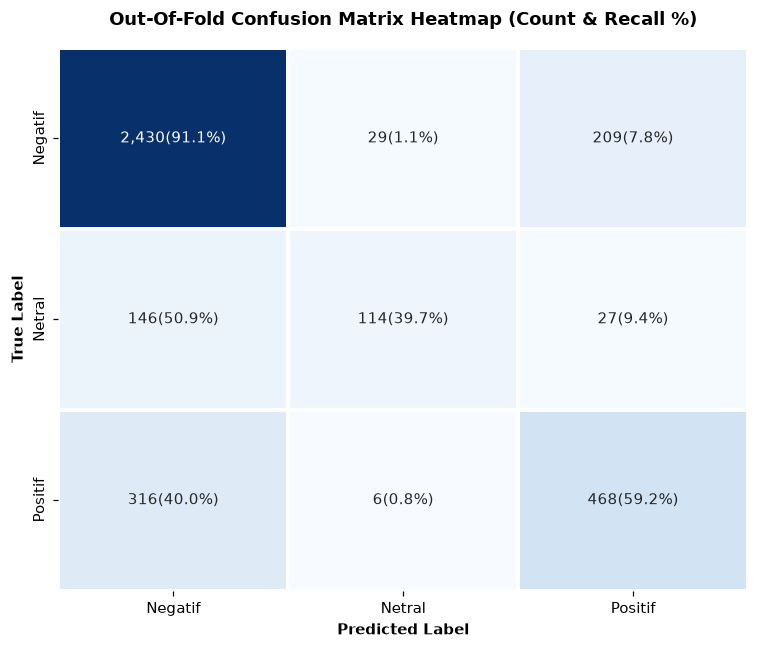

Detailed Classification Report:
              precision    recall  f1-score   support

     Negatif     0.8402    0.9108    0.8741      2668
      Netral     0.7651    0.3972    0.5229       287
     Positif     0.6648    0.5924    0.6265       790

    accuracy                         0.8043      3745
   macro avg     0.7567    0.6335    0.6745      3745
weighted avg     0.7975    0.8043    0.7950      3745



In [9]:
# 6. Diagnostic Evaluation: Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(7, 6))
classes = sorted(list(set(labels)))
cm = confusion_matrix(labels, oof_preds, labels=classes)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
annot_labels = np.array([[f'{count:,}({pct:.1f}%)' for count, pct in zip(row_c, row_p)] for row_c, row_p in zip(cm, cm_pct)])

sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=False, ax=ax, linewidths=1.5, linecolor='white')
ax.set_title('Out-Of-Fold Confusion Matrix Heatmap (Count & Recall %)', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Predicted Label', fontweight='bold')
ax.set_ylabel('True Label', fontweight='bold')
plt.tight_layout()
plt.show()

print('Detailed Classification Report:')
print(classification_report(labels, oof_preds, digits=4))

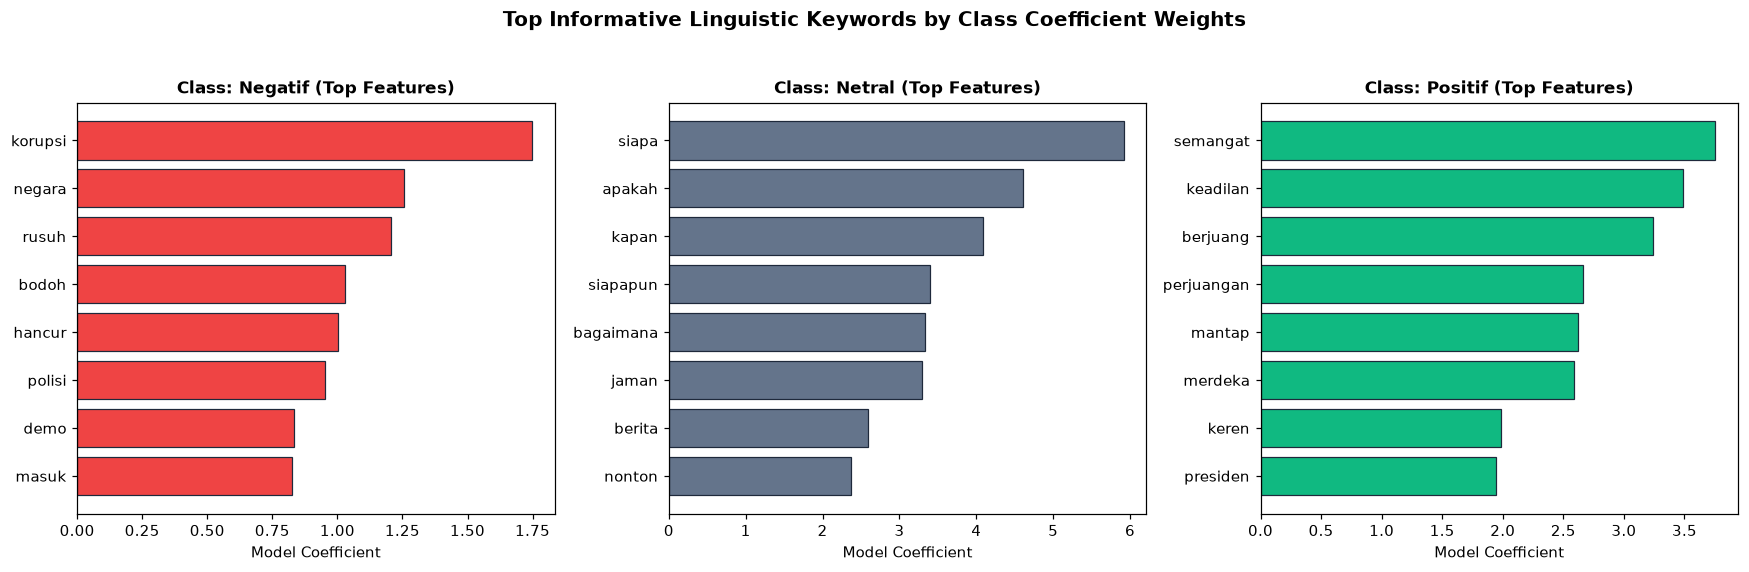

In [10]:
# 7. Model Explainability: Linguistic Keywords by Class Coefficient Weights
champion_clf = LogisticRegression(C=C_champ, max_iter=250, tol=1e-3, class_weight='balanced', random_state=SEED)
champion_clf.fit(X_champ, labels)
feature_names = np.array(champion['vec'].get_feature_names_out())

fig, axes = plt.subplots(1, len(champion_clf.classes_), figsize=(16, 5), sharey=False)
color_map = {'Negatif': '#ef4444', 'Netral': '#64748b', 'Positif': '#10b981', 'negative': '#ef4444', 'neutral': '#64748b', 'positive': '#10b981'}

for idx, cls_name in enumerate(champion_clf.classes_):
    coefs = champion_clf.coef_[idx] if len(champion_clf.classes_) > 2 else champion_clf.coef_[0]
    top_k = 8
    top_idx = np.argsort(coefs)[-top_k:]
    top_terms = feature_names[top_idx]
    top_vals = coefs[top_idx]
    
    ax_curr = axes[idx] if len(champion_clf.classes_) > 1 else axes
    ax_curr.barh(top_terms, top_vals, color=color_map.get(cls_name, '#3b82f6'), edgecolor='#1e293b', linewidth=0.8)
    ax_curr.set_title(f'Class: {cls_name} (Top Features)', fontsize=11, fontweight='bold')
    ax_curr.set_xlabel('Model Coefficient')

plt.suptitle('Top Informative Linguistic Keywords by Class Coefficient Weights', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


In [11]:
# 8. Test Inference & Submission Generation
resolved_test = resolve_path(TEST_PATH)
if resolved_test and os.path.exists(resolved_test):
    test_df = pd.read_csv(resolved_test)
    print(f'Test dataset loaded: {test_df.shape[0]:,} rows')
    X_test = champion['vec'].transform(test_df[TEXT_COL].astype(str))
    test_preds = champion_clf.predict(X_test)
    
    sub_df = pd.DataFrame()
    id_col = 'id' if 'id' in test_df.columns else ('reviewId' if 'reviewId' in test_df.columns else None)
    if id_col:
        sub_df[id_col] = test_df[id_col]
    else:
        sub_df['id'] = np.arange(len(test_df))
    sub_df[TARGET_COL] = test_preds
    sub_df.to_csv('submission.csv', index=False)
    print('Predictions saved successfully to submission.csv')
    display(sub_df.head())
else:
    print('No test dataset specified. Full pipeline training and diagnostics complete.')


No test dataset specified. Full pipeline training and diagnostics complete.
